In [1]:
import sys; sys.path.append("..")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (average_precision_score, precision_recall_curve, precision_score,
                             recall_score, f1_score, confusion_matrix)
from src.features import build_features, FEATURES
OUT = Path("../reports/fraud"); FIG = OUT / "figures"
raw = pd.read_csv("../../data/synthetic/synthetic_transactions_behavioral_v2.csv")
f = build_features(raw).merge(raw[["txn_id", "fraud_label", "fraud_reason"]], on="txn_id")
d = f[f.n_prior >= 20].sort_values("timestamp").reset_index(drop=True)
q60, q80 = d.timestamp.quantile([0.6, 0.8])
train, val, test = d[d.timestamp <= q60], d[(d.timestamp > q60) & (d.timestamp <= q80)], d[d.timestamp > q80]
for n, x in [("train", train), ("val", val), ("test", test)]:
    print(n, len(x), int(x.fraud_label.sum()), f"{x.fraud_label.mean():.3%}", x.timestamp.min().date(), "->", x.timestamp.max().date())

train 12894 98 0.760% 2025-06-26 -> 2026-04-26
val 4298 36 0.838% 2026-04-26 -> 2026-07-31
test 4298 29 0.675% 2026-07-31 -> 2026-10-31


In [2]:
COST_FN, COST_FP = 5, 1
def pick_threshold(y, s):
    cands = np.unique(np.quantile(s, np.linspace(0.90, 0.9999, 400)))
    return min(cands, key=lambda t: COST_FN*((s < t) & (y == 1)).sum() + COST_FP*((s >= t) & (y == 0)).sum())
def evaluate(name, y, s, thr):
    pred = (s >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return dict(model=name, pr_auc=average_precision_score(y, s), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred), f1=f1_score(y, pred), TP=tp, FP=fp, FN=fn, TN=tn)
y_tr, y_val, y_te = train.fraud_label.values, val.fraud_label.values, test.fraud_label.values
rows, scores, thrs = [], {}, {}
rows.append(evaluate("Rule: amount z-score > 3", y_te, (test.amount_z_user.fillna(0) > 3).astype(float).values, 0.5))
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
lr.fit(train[FEATURES], y_tr)
s_val, s_te = lr.predict_proba(val[FEATURES])[:, 1], lr.predict_proba(test[FEATURES])[:, 1]
scores["Logistic Regression"] = s_te; thrs["Logistic Regression"] = pick_threshold(y_val, s_val)
rows.append(evaluate("Logistic Regression", y_te, s_te, thrs["Logistic Regression"]))

In [3]:
import xgboost as xgb
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
m = xgb.XGBClassifier(n_estimators=500, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                      scale_pos_weight=spw, tree_method="hist", eval_metric="aucpr",
                      early_stopping_rounds=30, random_state=42, n_jobs=-1)
m.fit(train[FEATURES], y_tr, eval_set=[(val[FEATURES], y_val)], verbose=False)
s_val, s_te = m.predict_proba(val[FEATURES])[:, 1], m.predict_proba(test[FEATURES])[:, 1]
scores["XGBoost"] = s_te; thrs["XGBoost"] = pick_threshold(y_val, s_val)
rows.append(evaluate("XGBoost", y_te, s_te, thrs["XGBoost"]))
print("best iteration:", m.best_iteration)

best iteration: 23


,model,pr_auc,precision,recall,f1,TP,FP,FN,TN,cost_5FN_1FP
0,Rule: amount z-score > 3,NaN,0.0372,0.2414,0.0645,7,181,22,4088,291
1,Logistic Regression,0.1873,0.2419,0.5172,0.3297,15,47,14,4222,117
2,XGBoost,0.2645,0.2436,0.6552,0.3551,19,59,10,4210,109


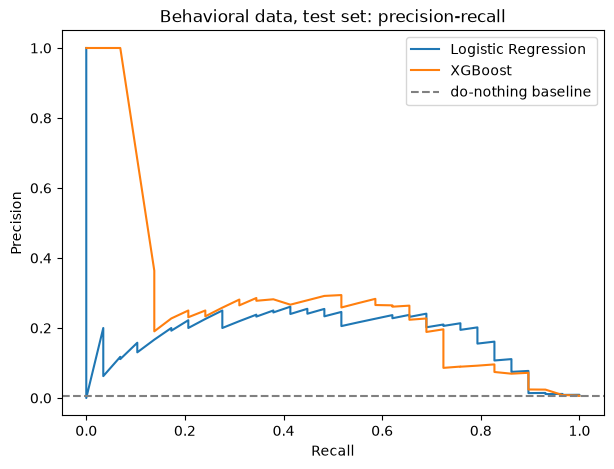

In [4]:
res = pd.DataFrame(rows); res["cost_5FN_1FP"] = 5 * res.FN + res.FP
res.loc[res.model.str.startswith("Rule"), "pr_auc"] = np.nan
res = res.round(4); res.to_csv(OUT / "behavioral_benchmark.csv", index=False); display(res)
plt.figure(figsize=(7, 5))
for name, s in scores.items():
    p, r, _ = precision_recall_curve(y_te, s); plt.plot(r, p, label=name)
plt.axhline(y_te.mean(), color="gray", linestyle="--", label="do-nothing baseline")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend(); plt.title("Behavioral data, test set: precision-recall")
plt.savefig(FIG / "behavioral_pr_curves.png", dpi=150, bbox_inches="tight"); plt.show()

In [5]:
te = test.assign(pred=(scores["XGBoost"] >= thrs["XGBoost"]).astype(int))
inj = te[te.fraud_reason.notna() & (te.fraud_reason != "hard_negative_large_legitimate")]
g = inj.groupby("fraud_reason")
summary = pd.DataFrame({"events": g.size(), "labelled_fraud": g.fraud_label.sum(), "flagged_all_events": g.pred.mean(),
                        "recall_on_labelled": inj[inj.fraud_label == 1].groupby("fraud_reason").pred.mean()}).round(2)
display(summary)
hn = te[te.fraud_reason == "hard_negative_large_legitimate"]
print("hard negatives flagged:", int(hn.pred.sum()), "of", len(hn))
print("labelled fraud caught:", round(inj[inj.fraud_label == 1].pred.mean(), 2), "| unlabelled injected flagged:", round(inj[inj.fraud_label == 0].pred.mean(), 2))
pd.Series(m.feature_importances_, index=FEATURES).sort_values(ascending=False).round(3).head(8)

,events,labelled_fraud,flagged_all_events,recall_on_labelled
fraud_reason,,,,
amount_anomaly,5,4,0.80,0.75
cash_out,3,3,0.67,0.67
new_city,10,4,1.00,1.00
new_device,5,2,1.00,1.00
new_merchant_high_amount,2,2,1.00,1.00
odd_hour,4,0,1.00,NaN
velocity,30,14,0.67,0.43


hard negatives flagged: 10 of 12
labelled fraud caught: 0.66 | unlabelled injected flagged: 0.93


is_new_device        0.137
txn_1h               0.129
is_new_city          0.114
amount_ratio_cat     0.103
secs_since_last      0.090
is_night             0.087
hour_bucket_share    0.075
hour                 0.062
dtype: float32

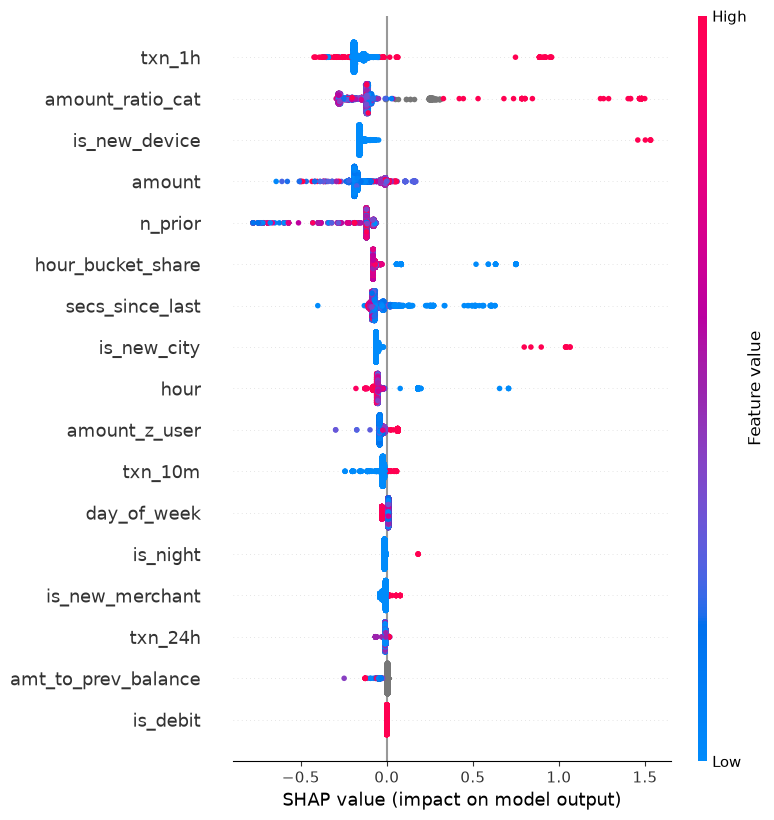

TXN00000537 | label=0 | nan | score=0.59
   facts: {'amount': 17457.05, 'amount_ratio_cat': 2.98, 'is_new_device': 0.0, 'is_new_city': 0.0, 'is_new_merchant': 0.0, 'txn_10m': 0.0, 'secs_since_last': 268315.0, 'is_night': 0.0}
   - The amount is 3.0x your usual spend in this category
TXN00006796 | label=1 | new_city | score=0.64
   facts: {'amount': 11330.13, 'amount_ratio_cat': 1.17, 'is_new_device': 0.0, 'is_new_city': 1.0, 'is_new_merchant': 0.0, 'txn_10m': 0.0, 'secs_since_last': 586459.0, 'is_night': 0.0}
   - This is the first time you have transacted from this city
   - Only 3% of your earlier transactions happened at this time of day
TXN00013290 | label=0 | hard_negative_large_legitimate | score=0.79
   facts: {'amount': 15000.0, 'amount_ratio_cat': 12.8, 'is_new_device': 0.0, 'is_new_city': 0.0, 'is_new_merchant': 0.0, 'txn_10m': 0.0, 'secs_since_last': 190638.0, 'is_night': 0.0}
   - The amount is 12.8x your usual spend in this category
TXN00021438 | label=0 | hard_negative_la

In [6]:
import json, shap
from src.explain import top_reasons, FALLBACK
ART = Path("../artifacts"); ART.mkdir(exist_ok=True)
m.save_model(ART / "fraud_v2.json")
xr = res[res.model == "XGBoost"].iloc[0]
with open(ART / "fraud_v2_meta.json", "w") as fh:
    json.dump({"model_version": "fraud_v2", "features": FEATURES, "threshold": float(thrs["XGBoost"]),
               "test_pr_auc": float(xr.pr_auc), "test_precision": float(xr.precision), "test_recall": float(xr.recall)}, fh, indent=2)
explainer = shap.TreeExplainer(m)
Xte = test[FEATURES]
sv = explainer.shap_values(Xte)
assert sv.shape == Xte.shape
shap.summary_plot(sv, Xte, show=False)
plt.savefig(FIG / "shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()
flagged = np.where(scores["XGBoost"] >= thrs["XGBoost"])[0]
SHOW = ["amount", "amount_ratio_cat", "is_new_device", "is_new_city", "is_new_merchant", "txn_10m", "secs_since_last", "is_night"]
for i in flagged[:20]:
    r = test.iloc[i]
    print(f"{r.txn_id} | label={int(r.fraud_label)} | {r.fraud_reason} | score={scores['XGBoost'][i]:.2f}")
    print("   facts:", {k: (round(float(r[k]), 2) if pd.notna(r[k]) else None) for k in SHOW})
    for s in (top_reasons(sv[i], Xte.iloc[i], FEATURES) or [FALLBACK]):
        print("   -", s)

In [7]:
from importlib import reload
import src.explain as ex; reload(ex)
from src.explain import top_reasons, FALLBACK
tp = np.where((scores["XGBoost"] >= thrs["XGBoost"]) & (y_te == 1))[0]
FACTS = ["amount", "amount_ratio_cat", "amount_z_user", "is_new_device", "is_new_city", "is_new_merchant",
         "txn_10m", "txn_1h", "secs_since_last", "is_night", "hour_bucket_share", "amt_to_prev_balance"]
cases = []
for i in tp:
    r = test.iloc[i]
    reasons = top_reasons(sv[i], Xte.iloc[i], FEATURES) or [FALLBACK]
    cases.append({"txn_id": r.txn_id, "pattern": r.fraud_reason, "score": round(float(scores["XGBoost"][i]), 2),
                  **{k: (round(float(r[k]), 2) if pd.notna(r[k]) else None) for k in FACTS},
                  "reasons": " | ".join(reasons)})
cases = pd.DataFrame(cases)
cases.to_csv(OUT / "explanation_cases.csv", index=False)
print(len(cases), "true-positive cases;", (cases.reasons == FALLBACK).sum(), "fell back to the generic sentence")
pd.set_option("display.max_colwidth", None); pd.set_option("display.width", 250)
display(cases[["txn_id", "pattern", "score", "reasons"]])

19 true-positive cases; 1 fell back to the generic sentence


,txn_id,pattern,score,reasons
0,TXN00006796,new_city,0.64,This is the first time you have transacted from this city | Only 3% of your earlier transactions happened at this time of day
1,TXN00014740,new_merchant_high_amount,0.80,The amount is 4.7x your usual spend in this category | This is the first time you have paid this merchant
2,TXN00021604,amount_anomaly,0.70,The amount is 6.5x your usual spend in this category
3,TXN00022902,new_device,0.75,This is the first time you have used this device | The amount is 2.7 standard deviations above your normal spending
4,TXN00020804,velocity,0.60,Only 78 seconds since your previous transaction | 2 other transactions in the last 10 minutes
5,TXN00020807,velocity,0.60,5 other transactions in the last hour | Only 38 seconds since your previous transaction
6,TXN00015502,velocity,0.60,Only 79 seconds since your previous transaction | 2 other transactions in the last 10 minutes
7,TXN00015503,velocity,0.58,3 other transactions in the last hour
8,TXN00013310,new_city,0.66,This is the first time you have transacted from this city
9,TXN00012294,velocity,0.59,This transaction is unusual compared with your normal behaviour
